# Notebook 20 — Rolling-Origin Backtesting and Persistence Analysis

**Project:** Dengue Disease Prediction, Sri Lanka · 25 districts · one-month-ahead district-level case forecasts.

**Main research questions**
1. Why does the previous-month **persistence** forecast perform so well?
2. Does a **compact 7-feature LSTM** improve on persistence consistently across **2016–2017, 2018–2019, 2020–2021, and 2022–2023**?
3. Does adding current-month weather measurements improve a **matched** dengue-history + seasonality model?

**Inputs:** Notebook 11's *unscaled* `data/final/dengue_temporal_features_weather_only_2010_2024.csv`, its predictor schema JSON, and Notebook 09's `data/processed/dengue_weather_monthly_2010_2024.csv` (for historical baselines). Do **not** use the pre-scaled Notebook 12 arrays: they were fitted for a later training split and are not valid for early folds.

**Protocol:** Four expanding training windows; six-month LSTM inputs; scalers fit separately within each fold's model-fitting subset; internal last-12-month early stopping; 2024 excluded from analysis. **This is retrospective exploratory backtesting**, not a fresh independent test, because earlier notebooks have already examined later data.

**Outputs:** `results/tables/notebook20_*.csv`, `results/figures/notebook20_*.png`, and `results/metrics/notebook20_protocol.json`. Nothing is written to `models/`.

## 1 — Setup

Run in the existing `.venv` Jupyter kernel. Required packages: `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `tensorflow`, `IPython`. Training uses the same simple **LSTM(32) → Dense(16) → Dropout(0.2) → Dense(1)** architecture as Notebook 17. To reduce laptop runtime, the default executes **two models × three seeds × four folds = 24 LSTM fits**. Set `SEEDS=(42,)` for a quick smoke test, then restore all three seeds for research results.

In [1]:
from pathlib import Path
import json, random, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'data'/'final'/'dengue_temporal_features_weather_only_2010_2024.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run Notebook 11, then open D:\Dengue_Project or its notebooks/ directory.')
FINAL=ROOT/'data'/'final'; PROCESSED=ROOT/'data'/'processed'
TABLES=ROOT/'results'/'tables'; FIGS=ROOT/'results'/'figures'; METRICS=ROOT/'results'/'metrics'
for p in (TABLES, FIGS, METRICS): p.mkdir(parents=True,exist_ok=True)
try:
    import tensorflow as tf
except ImportError as exc:
    raise ImportError('Install TensorFlow into the selected VS Code .venv kernel.') from exc

SEEDS=(42,123,2026)  # smoke test: (42,)
MAX_EPOCHS=40
PATIENCE=6
BATCH_SIZE=32
LEARNING_RATE=0.001
DROPOUT=0.2
SEQ_LEN=6
INTERNAL_VAL_MONTHS=12
BOOTSTRAP_REPS=1000
BOOTSTRAP_SEED=2026
RUN_EXTRA_MODELS=False  # True also trains 9-feature history and full 33-feature models

FOLDS=[('2016-2017','2015-12-01','2016-01-01','2017-12-01'),
       ('2018-2019','2017-12-01','2018-01-01','2019-12-01'),
       ('2020-2021','2019-12-01','2020-01-01','2021-12-01'),
       ('2022-2023','2021-12-01','2022-01-01','2023-12-01')]
print('Project:',ROOT,'| TensorFlow:',tf.__version__)
print('LSTM fits planned:',len(FOLDS)*len(SEEDS)*(2+2*int(RUN_EXTRA_MODELS)))

Project: d:\Dengue_Project | TensorFlow: 2.21.0
LSTM fits planned: 24


## 2 — Load the unscaled feature table and verify its schema

The feature row for month **t** predicts dengue in **t+1**. We immediately remove all rows whose **target month** falls in 2024 or later. No 2024 target is used for fitting, scaling, selection, or evaluation. The source CSV can contain historical records from 2024, but they are excluded before any calculation.

In [2]:
FEATURE_PATH=FINAL/'dengue_temporal_features_weather_only_2010_2024.csv'
SCHEMA_PATH=FINAL/'notebook11_temporal_feature_schema.json'
RAW_PATH=PROCESSED/'dengue_weather_monthly_2010_2024.csv'
for p in (FEATURE_PATH,SCHEMA_PATH,RAW_PATH):
    if not p.is_file(): raise FileNotFoundError(f'Required project input not found: {p}')
schema=json.loads(SCHEMA_PATH.read_text(encoding='utf-8'))
ALL_FEATURES=schema['weather_only_predictors']
TARGET=schema['forecast_target']
assert TARGET=='target_dengue_cases_t_plus_1'
frame=pd.read_csv(FEATURE_PATH,parse_dates=['date','target_date'])
frame=frame.loc[frame['target_date']<pd.Timestamp('2024-01-01')].copy()
frame=frame.sort_values(['administrative_district','date']).reset_index(drop=True)
raw=pd.read_csv(RAW_PATH,parse_dates=['date'])
raw=raw.loc[raw['date']<pd.Timestamp('2024-01-01')].copy()
required=['administrative_district','date','target_date',TARGET]+ALL_FEATURES
assert set(required).issubset(frame.columns)
assert not frame.duplicated(['administrative_district','date']).any()
assert not frame.duplicated(['administrative_district','target_date']).any()
assert frame['administrative_district'].nunique()==25
assert (frame['target_date']==frame['date']+pd.offsets.MonthBegin(1)).all()
assert frame[ALL_FEATURES+[TARGET]].notna().all().all()
assert np.isfinite(frame[ALL_FEATURES+[TARGET]].to_numpy(float)).all()
assert frame[TARGET].ge(0).all()
assert frame['target_date'].max()==pd.Timestamp('2023-12-01')
assert not raw.duplicated(['administrative_district','date']).any()
assert raw['administrative_district'].nunique()==25
lookup=raw.set_index(['administrative_district','date'])['dengue_cases']
print('Available eligible feature rows (through 2023):',len(frame))
print('Earliest target:',frame.target_date.min().date(),'| Latest target:',frame.target_date.max().date())
print('Predictors:',len(ALL_FEATURES))
display(frame[['administrative_district','date','target_date','dengue_cases',TARGET]].head())

Available eligible feature rows (through 2023): 4025
Earliest target: 2010-08-01 | Latest target: 2023-12-01
Predictors: 33


,administrative_district,date,target_date,dengue_cases,target_dengue_cases_t_plus_1
0,Ampara,2010-07-01,2010-08-01,31.428571,20.714286
1,Ampara,2010-08-01,2010-09-01,20.714286,11.000000
2,Ampara,2010-09-01,2010-10-01,11.000000,11.142857
3,Ampara,2010-10-01,2010-11-01,11.142857,23.000000
4,Ampara,2010-11-01,2010-12-01,23.000000,13.000000


## 3 — Prespecify feature groups and chronological folds

A **matched feature comparison** is essential: `current_dengue_season` (3 features) versus `compact_7` (the same three plus four contemporaneous weather variables). This isolates the incremental weather information **within the tested model**. Optional 9- and 33-feature groups are included for an additional complexity comparison; enabling them doubles the training cost.

The four outer validation folds cover eight distinct years. The training windows expand while each outer validation window remains **unseen during model fitting and early stopping**.

In [3]:
CORE=['dengue_cases','target_month_sin','target_month_cos']
WEATHER=['temperature_mean_c','humidity_mean_percent','rainfall_total_mm','wind_speed_mean_kmh']
COMPACT=['dengue_cases']+WEATHER+['target_month_sin','target_month_cos']
HISTORY=[f for f in ALL_FEATURES if f.startswith('dengue_cases')]+['target_month_sin','target_month_cos']
FEATURE_GROUPS={'current_dengue_season':CORE,'compact_7':COMPACT}
if RUN_EXTRA_MODELS:
    FEATURE_GROUPS.update({'history_9':HISTORY,'full_engineered_33':ALL_FEATURES})
for label, cols in FEATURE_GROUPS.items():
    assert len(cols)==len(set(cols)) and set(cols).issubset(ALL_FEATURES)
    print(f'{label:25s}: {len(cols)} features')
fold_table=pd.DataFrame(FOLDS,columns=['fold','train_target_end','validation_start','validation_end'])
fold_table.insert(1,'train_target_start','first available through sequence construction')
display(fold_table)
assert max(pd.Timestamp(x[3]) for x in FOLDS)<pd.Timestamp('2024-01-01')

current_dengue_season    : 3 features
compact_7                : 7 features


,fold,train_target_start,train_target_end,validation_start,validation_end
0,2016-2017,first available through sequence construction,2015-12-01,2016-01-01,2017-12-01
1,2018-2019,first available through sequence construction,2017-12-01,2018-01-01,2019-12-01
2,2020-2021,first available through sequence construction,2019-12-01,2020-01-01,2021-12-01
3,2022-2023,first available through sequence construction,2021-12-01,2022-01-01,2023-12-01


## 4 — Build raw six-month sequences once, without any global scaling

Each input sequence contains feature months **t−5 through t**, and predicts the target month **t+1**. Consecutive calendar months are checked explicitly. Building raw sequences before splitting is safe because all feature engineering in Notebook 11 uses current/past observations only; **scalers and model weights are never fitted globally**.

In [4]:
def make_raw_sequences(data, predictors, length=6):
    xs, ys, rows=[],[],[]
    for district, g in data.groupby('administrative_district',sort=True):
        g=g.sort_values('date').reset_index(drop=True)
        values=g[predictors].to_numpy(np.float32)
        dates=g['date'].to_numpy(dtype='datetime64[M]').astype('int64')
        for i in range(length-1,len(g)):
            indices=dates[i-length+1:i+1]
            if not np.all(np.diff(indices)==1): continue
            xs.append(values[i-length+1:i+1]); ys.append(float(g.loc[i,TARGET]))
            rows.append({'administrative_district':district,
                         'feature_date':g.loc[i,'date'],
                         'sequence_start_date':g.loc[i-length+1,'date'],
                         'target_date':g.loc[i,'target_date'],
                         'current_dengue_cases':float(g.loc[i,'dengue_cases'])})
    X=np.asarray(xs,dtype=np.float32)
    y=np.asarray(ys,dtype=np.float64)
    meta=pd.DataFrame(rows)
    assert len(X)==len(y)==len(meta)>0
    assert X.shape[1:]==(length,len(predictors))
    assert (meta.target_date==meta.feature_date+pd.offsets.MonthBegin(1)).all()
    assert np.isfinite(X).all() and np.isfinite(y).all()
    return X,y,meta

# First inspect the compact sequence coverage; other feature groups share these exact target keys.
X_check,y_check,m_check=make_raw_sequences(frame,COMPACT,SEQ_LEN)
print('Sequence tensor:',X_check.shape,'| targets:',m_check.target_date.min().date(),'to',m_check.target_date.max().date())
for name,end,start,stop in FOLDS:
    train_mask=m_check.target_date<=pd.Timestamp(end)
    val_mask=m_check.target_date.between(pd.Timestamp(start),pd.Timestamp(stop))
    print(name,'train',int(train_mask.sum()),'validation',int(val_mask.sum()))
    assert val_mask.sum()==25*24, 'Expected 25 districts × 24 months per validation fold'
    assert train_mask.sum()>0

Sequence tensor: (3900, 6, 7) | targets: 2011-01-01 to 2023-12-01
2016-2017 train 1500 validation 600
2018-2019 train 2100 validation 600
2020-2021 train 2700 validation 600
2022-2023 train 3300 validation 600


## 5 — Explain persistence before training any neural network

Persistence predicts **next month = current month**. The seasonal naïve method predicts **next month = the same month one year earlier**. Both use genuinely available historical dengue counts. We measure district-level lag-1 correlations and changes in dengue activity. Correlation is descriptive, not a causal explanation.

In [5]:
def historical_prediction(meta,months_back):
    idx=pd.MultiIndex.from_arrays(
        [meta['administrative_district'].to_numpy(),
         (meta['target_date']-pd.DateOffset(months=months_back)).to_numpy()],
        names=['administrative_district','date'])
    values=lookup.reindex(idx).to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError(f'Missing historical dengue values for {months_back}-month baseline')
    return values

def metrics(actual,pred):
    a=np.asarray(actual,dtype=float).reshape(-1)
    p=np.asarray(pred,dtype=float).reshape(-1)
    assert a.shape==p.shape and np.isfinite(a).all() and np.isfinite(p).all()
    return {'MAE_cases':float(mean_absolute_error(a,p)),
            'RMSE_cases':float(np.sqrt(mean_squared_error(a,p))),
            'WAPE_percent':float(100*np.sum(np.abs(a-p))/np.sum(a)) if a.sum()>0 else np.nan,
            'bias_cases':float(np.mean(p-a)),
            'R2':float(r2_score(a,p)) if len(a)>1 else np.nan}

persistence=historical_prediction(m_check,1)
assert np.allclose(persistence,m_check.current_dengue_cases)
seasonal=historical_prediction(m_check,12)
assert np.allclose(y_check,frame.set_index(['administrative_district','target_date'])
                   .loc[pd.MultiIndex.from_frame(m_check[['administrative_district','target_date']]),TARGET].to_numpy())

# Correlations across the 24 target months in each fold, plus district-level values.
autocorr_rows=[]
for fold,_,start,end in FOLDS:
    mask=m_check.target_date.between(pd.Timestamp(start),pd.Timestamp(end))
    m=m_check.loc[mask].reset_index(drop=True); actual=y_check[mask.to_numpy()]; prior=persistence[mask.to_numpy()]
    autocorr_rows.append({'fold':fold,'district':'ALL_POOLED','n':len(actual),
                          'pearson_lag1':float(np.corrcoef(prior,actual)[0,1])})
    for district in sorted(m.administrative_district.unique()):
        take=m.administrative_district.eq(district).to_numpy()
        autocorr_rows.append({'fold':fold,'district':district,'n':int(take.sum()),
                              'pearson_lag1':float(np.corrcoef(prior[take],actual[take])[0,1])})
autocorr=pd.DataFrame(autocorr_rows)
display(autocorr[autocorr.district.eq('ALL_POOLED')])
print('Correlation can be high even when forecast errors are large during sudden outbreaks.')

,fold,district,n,pearson_lag1
0,2016-2017,ALL_POOLED,600,0.741112
26,2018-2019,ALL_POOLED,600,0.898726
52,2020-2021,ALL_POOLED,600,0.863210
78,2022-2023,ALL_POOLED,600,0.756415


Correlation can be high even when forecast errors are large during sudden outbreaks.


## 6 — Predefine outbreak-change categories and high-incidence thresholds

For interpretation only, label a target month as **surge** if cases rise by at least **50** *and* at least **25%** relative to the previous month; **decline** for a similarly large drop; otherwise **stable/moderate change**. These labels use actual future outcomes only for **post-hoc error analysis**, never as predictors.

High-incidence threshold is the **90th percentile of training target counts within each fold**, so it never uses outer-validation outcomes to define the threshold.

In [6]:
def regime_labels(actual,previous):
    actual=np.asarray(actual,float); previous=np.asarray(previous,float)
    delta=actual-previous
    relative=np.abs(delta)/np.maximum(previous,1.0)
    large=(np.abs(delta)>=50)&(relative>=0.25)
    return np.where(large&(delta>0),'surge',np.where(large&(delta<0),'decline','stable_or_moderate'))

# Baseline errors by regime, pooled across all outer validation folds.
baseline_rows=[];baseline_predictions=[]
for fold,train_end,start,end in FOLDS:
    mask=m_check.target_date.between(pd.Timestamp(start),pd.Timestamp(end)).to_numpy()
    train_mask=m_check.target_date.le(pd.Timestamp(train_end)).to_numpy()
    y=y_check[mask]; m=m_check.loc[mask].reset_index(drop=True)
    high_threshold=float(np.quantile(y_check[train_mask],.90))
    for model,pred in [('persistence',persistence[mask]),('seasonal_naive',seasonal[mask])]:
        baseline_rows.append({'fold':fold,'model':model,'seed':'deterministic','n':len(y),**metrics(y,pred)})
        p=m[['administrative_district','target_date']].copy()
        p['fold']=fold;p['model']=model;p['seed']='deterministic'
        p['actual_cases']=y;p['predicted_cases']=pred
        p['previous_month_cases']=persistence[mask]
        p['regime']=regime_labels(y,persistence[mask]);p['high_incidence']=y>=high_threshold
        p['training_high_threshold']=high_threshold
        baseline_predictions.append(p)
baseline_metrics=pd.DataFrame(baseline_rows)
baseline_predictions=pd.concat(baseline_predictions,ignore_index=True)
display(baseline_metrics[['fold','model','MAE_cases','RMSE_cases','bias_cases']])
print('Regime counts:')
display(baseline_predictions.query("model == 'persistence'").groupby(['fold','regime']).size().rename('n').reset_index())

,fold,model,MAE_cases,RMSE_cases,bias_cases
0,2016-2017,persistence,190.414048,555.175284,-11.402143
1,2016-2017,seasonal_naive,267.923095,731.208387,-254.562143
2,2018-2019,persistence,86.405952,181.461941,-12.205476
3,2018-2019,seasonal_naive,329.905476,756.578449,131.777381
4,2020-2021,persistence,55.287619,142.477435,22.578095
5,2020-2021,seasonal_naive,189.111429,435.327435,126.827143
6,2022-2023,persistence,77.130476,170.158791,-15.833810
7,2022-2023,seasonal_naive,118.018095,257.721501,-90.552857


Regime counts:


,fold,regime,n
0,2016-2017,decline,100
1,2016-2017,stable_or_moderate,358
2,2016-2017,surge,142
3,2018-2019,decline,81
4,2018-2019,stable_or_moderate,416
5,2018-2019,surge,103
6,2020-2021,decline,85
7,2020-2021,stable_or_moderate,463
8,2020-2021,surge,52
9,2022-2023,decline,92


## 7 — Define fold-specific scaling and LSTM training

**Critical leakage protection:** The outer fold is never passed to `.fit()` or `EarlyStopping`. The **last 12 target months of the expanding training window** form an *inner* early-stopping period. StandardScaler is fitted on the remaining *inner training* sequences only, then applied unchanged to inner validation and outer validation. Target is transformed with `log1p` and predictions are converted back with `expm1`.

We deliberately do **not** retrain after early stopping; the last training year is reserved for model selection. This is consistent across folds and feature groups but sacrifices some fitting data. We record that limitation.

In [7]:
def make_network(input_shape,lr=LEARNING_RATE,dropout=DROPOUT):
    net=tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.LSTM(32),
        tf.keras.layers.Dense(16,activation='relu'),
        tf.keras.layers.Dropout(dropout),
        tf.keras.layers.Dense(1)])
    net.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),loss='mse')
    return net

def split_fold(meta,train_end,val_start,val_end,inner_months=12):
    end=pd.Timestamp(train_end);start=pd.Timestamp(val_start);stop=pd.Timestamp(val_end)
    inner_start=end-pd.DateOffset(months=inner_months-1)
    fitting=(meta.target_date<inner_start).to_numpy()
    inner=meta.target_date.between(inner_start,end).to_numpy()
    outer=meta.target_date.between(start,stop).to_numpy()
    assert fitting.sum()>100 and inner.sum()==25*inner_months and outer.sum()==25*24
    assert not np.any(fitting&inner) and not np.any(fitting&outer) and not np.any(inner&outer)
    assert meta.target_date.loc[fitting].max()<inner_start
    assert meta.target_date.loc[inner].max()<start
    return fitting,inner,outer,inner_start

def train_and_predict(X,y,meta,fold_spec,seed):
    fold,train_end,val_start,val_end=fold_spec
    fit,inner,outer,inner_start=split_fold(meta,train_end,val_start,val_end,INTERNAL_VAL_MONTHS)
    # Every scaler is fitted only on training sequences, never on the inner or outer validation set.
    scaler=StandardScaler()
    scaler.fit(X[fit].reshape(-1,X.shape[-1]))
    def transform(mask):
        selected=X[mask]
        return scaler.transform(selected.reshape(-1,X.shape[-1])).reshape(selected.shape).astype(np.float32)
    X_fit=transform(fit); X_inner=transform(inner); X_outer=transform(outer)
    assert np.isfinite(X_fit).all() and np.isfinite(X_inner).all() and np.isfinite(X_outer).all()
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(int(seed))
    random.seed(int(seed));np.random.seed(int(seed))
    net=make_network(X_fit.shape[1:])
    hist=net.fit(X_fit,np.log1p(y[fit]).astype(np.float32),
                 validation_data=(X_inner,np.log1p(y[inner]).astype(np.float32)),
                 epochs=MAX_EPOCHS,batch_size=BATCH_SIZE,shuffle=False,verbose=0,
                 callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=PATIENCE,
                                                              restore_best_weights=True)])
    log_predictions=net.predict(X_outer,verbose=0).reshape(-1)
    predicted=np.maximum(0,np.expm1(np.clip(log_predictions,-20,20)))
    result={'n_fitting':int(fit.sum()),'n_inner':int(inner.sum()),'n_outer':int(outer.sum()),
            'inner_validation_start':str(inner_start.date()),
            'epochs_run':len(hist.history['loss']),
            'best_inner_val_loss':float(min(hist.history['val_loss'])),
            'scaler_fit_target_end':str(meta.target_date.loc[fit].max().date())}
    tf.keras.backend.clear_session();del net;gc.collect()
    return predicted,outer,result

## 8 — Run expanding-window LSTM comparisons

Each outer fold evaluates exactly 600 district-month targets. The compact model and its matched 3-feature comparator are trained on **identical target observations** and **identical random seeds**. A progress line prints after each fit. This cell can take considerable time on a laptop.

In [8]:
model_rows=[];model_predictions=[]
reference_keys=None
for group_name,features in FEATURE_GROUPS.items():
    X,y,meta=make_raw_sequences(frame,features,SEQ_LEN)
    keys=pd.MultiIndex.from_frame(meta[['administrative_district','target_date']])
    if reference_keys is None: reference_keys=keys
    else: assert keys.equals(reference_keys),'Feature groups must have exactly matched target rows'
    assert np.allclose(y,y_check)
    for fold_spec in FOLDS:
        fold=fold_spec[0]
        for seed in SEEDS:
            prediction,outer,info=train_and_predict(X,y,meta,fold_spec,seed)
            actual=y[outer]
            row={'fold':fold,'model':group_name,'seed':int(seed),'n_features':len(features),
                 **info,**metrics(actual,prediction)}
            model_rows.append(row)
            out=meta.loc[outer,['administrative_district','target_date']].reset_index(drop=True)
            out['fold']=fold;out['model']=group_name;out['seed']=int(seed)
            out['actual_cases']=actual;out['predicted_cases']=prediction
            previous=historical_prediction(out,1)
            out['previous_month_cases']=previous
            out['regime']=regime_labels(actual,previous)
            train_targets=y[meta.target_date.le(pd.Timestamp(fold_spec[1])).to_numpy()]
            threshold=float(np.quantile(train_targets,.90))
            out['high_incidence']=actual>=threshold
            out['training_high_threshold']=threshold
            model_predictions.append(out)
            print(f'{fold:9s} | {group_name:24s} | seed={seed} | MAE={row["MAE_cases"]:.2f} '
                  f'| RMSE={row["RMSE_cases"]:.2f} | epochs={info["epochs_run"]}')
model_metrics=pd.DataFrame(model_rows)
model_predictions=pd.concat(model_predictions,ignore_index=True)
all_predictions=pd.concat([baseline_predictions,model_predictions],ignore_index=True)
all_metrics=pd.concat([baseline_metrics,model_metrics],ignore_index=True)
assert all_predictions.target_date.lt(pd.Timestamp('2024-01-01')).all()
print('LSTM fits completed:',len(model_metrics),'| Total prediction rows:',len(all_predictions))
display(model_metrics[['fold','model','seed','MAE_cases','RMSE_cases','bias_cases']])


2016-2017 | current_dengue_season    | seed=42 | MAE=216.15 | RMSE=701.16 | epochs=40
2016-2017 | current_dengue_season    | seed=123 | MAE=198.63 | RMSE=595.07 | epochs=40
2016-2017 | current_dengue_season    | seed=2026 | MAE=201.99 | RMSE=657.26 | epochs=40
2018-2019 | current_dengue_season    | seed=42 | MAE=103.32 | RMSE=251.72 | epochs=40
2018-2019 | current_dengue_season    | seed=123 | MAE=96.78 | RMSE=227.60 | epochs=40
2018-2019 | current_dengue_season    | seed=2026 | MAE=98.64 | RMSE=227.25 | epochs=35
2020-2021 | current_dengue_season    | seed=42 | MAE=48.51 | RMSE=120.46 | epochs=40
2020-2021 | current_dengue_season    | seed=123 | MAE=54.40 | RMSE=143.81 | epochs=40
2020-2021 | current_dengue_season    | seed=2026 | MAE=49.31 | RMSE=112.52 | epochs=40
2022-2023 | current_dengue_season    | seed=42 | MAE=84.62 | RMSE=181.40 | epochs=40
2022-2023 | current_dengue_season    | seed=123 | MAE=85.46 | RMSE=189.43 | epochs=40
2022-2023 | current_dengue_season    | seed=2026 |

,fold,model,seed,MAE_cases,RMSE_cases,bias_cases
0,2016-2017,current_dengue_season,42,216.150937,701.158744,-182.364982
1,2016-2017,current_dengue_season,123,198.633016,595.074040,-129.567101
2,2016-2017,current_dengue_season,2026,201.991866,657.262513,-160.830457
3,2018-2019,current_dengue_season,42,103.323881,251.717868,-68.113400
4,2018-2019,current_dengue_season,123,96.783046,227.601686,-56.445624
5,2018-2019,current_dengue_season,2026,98.639406,227.251117,-51.190137
6,2020-2021,current_dengue_season,42,48.512315,120.460378,7.272109
7,2020-2021,current_dengue_season,123,54.400724,143.808657,15.579182
8,2020-2021,current_dengue_season,2026,49.314079,112.521513,10.906969
9,2022-2023,current_dengue_season,42,84.623635,181.395354,-46.414382


## 9 — Compare models within each fold, across seeds and across years

Use MAE as the primary metric. **Do not select a winner based only on a pooled average**: examine the 2016–2017 outbreak period and the other folds separately. Each seed is a different training run on the same 600 target observations, not 600 new independent experiments.

In [9]:
summary=(all_metrics.groupby(['fold','model'],as_index=False)
         .agg(n_runs=('MAE_cases','size'),MAE_mean=('MAE_cases','mean'),
              MAE_sd=('MAE_cases','std'),RMSE_mean=('RMSE_cases','mean'),
              WAPE_mean=('WAPE_percent','mean'),bias_mean=('bias_cases','mean')))
summary['MAE_sd']=summary['MAE_sd'].fillna(0)
summary['rank_by_MAE']=summary.groupby('fold')['MAE_mean'].rank(method='min')
reference=summary.query("model == 'persistence'")[['fold','MAE_mean']].rename(columns={'MAE_mean':'persistence_MAE'})
summary=summary.merge(reference,on='fold',validate='many_to_one')
summary['improvement_vs_persistence_pct']=100*(summary['persistence_MAE']-summary['MAE_mean'])/summary['persistence_MAE']
display(summary.sort_values(['fold','MAE_mean']).round(3))
print('Across-fold mean MAE (each fold weighted equally):')
display(summary.groupby('model',as_index=False).agg(mean_fold_MAE=('MAE_mean','mean'),
         mean_improvement_pct=('improvement_vs_persistence_pct','mean'),
         folds_beating_persistence=('improvement_vs_persistence_pct',lambda x:int((x>0).sum())))
        .sort_values('mean_fold_MAE').round(3))

,fold,model,n_runs,MAE_mean,MAE_sd,RMSE_mean,WAPE_mean,bias_mean,rank_by_MAE,persistence_MAE,improvement_vs_persistence_pct
2,2016-2017,persistence,1,190.414,0.000,555.175,54.472,-11.402,1.0,190.414,0.000
1,2016-2017,current_dengue_season,3,205.592,9.297,651.165,58.814,-157.588,2.0,190.414,-7.971
0,2016-2017,compact_7,3,216.288,3.966,672.252,61.874,-163.777,3.0,190.414,-13.588
3,2016-2017,seasonal_naive,1,267.923,0.000,731.208,76.646,-254.562,4.0,190.414,-40.706
6,2018-2019,persistence,1,86.406,0.000,181.462,35.187,-12.205,1.0,86.406,0.000
5,2018-2019,current_dengue_season,3,99.582,3.371,235.524,40.553,-58.583,2.0,86.406,-15.249
4,2018-2019,compact_7,3,106.296,2.796,239.789,43.287,-89.914,3.0,86.406,-23.020
7,2018-2019,seasonal_naive,1,329.905,0.000,756.578,134.348,131.777,4.0,86.406,-281.809
9,2020-2021,current_dengue_season,3,50.742,3.193,125.597,60.140,11.253,1.0,55.288,8.221
8,2020-2021,compact_7,3,53.059,8.062,150.110,62.886,8.989,2.0,55.288,4.031


Across-fold mean MAE (each fold weighted equally):


,model,mean_fold_MAE,mean_improvement_pct,folds_beating_persistence
2,persistence,102.310,0.000,0
1,current_dengue_season,110.198,-6.260,1
0,compact_7,113.865,-9.015,1
3,seasonal_naive,226.240,-154.394,0


## 10 — Why persistence succeeds or fails: surge, decline, stable, and high incidence

We compare persistence with the two primary LSTM variants using the same observations. A large overall correlation does not guarantee low errors in surge periods. Regime labels are retrospective outcome categories, not deployable outbreak predictions.

In [10]:
def grouped_error_table(predictions,group_cols):
    rows=[]
    for keys,g in predictions.groupby(group_cols,dropna=False):
        keys=keys if isinstance(keys,tuple) else (keys,)
        rows.append({**dict(zip(group_cols,keys)),'n':len(g),
                     **metrics(g.actual_cases.to_numpy(),g.predicted_cases.to_numpy())})
    return pd.DataFrame(rows)

# One row per district-month for persistence; one row per district-month per seed for LSTM.
regime_metrics=grouped_error_table(all_predictions,['fold','model','seed','regime'])
incidence_metrics=grouped_error_table(all_predictions,['fold','model','seed','high_incidence'])
district_metrics=grouped_error_table(all_predictions,['fold','model','seed','administrative_district'])
print('Mean regime MAE over seeds (for each model/fold):')
display(regime_metrics.groupby(['model','regime'],as_index=False)
        .agg(mean_MAE=('MAE_cases','mean'),mean_bias=('bias_cases','mean'),n_fold_seed_groups=('n','size'))
        .sort_values(['regime','mean_MAE']).round(2))
print('High-incidence versus other target months:')
display(incidence_metrics.groupby(['model','high_incidence'],as_index=False)
        .agg(mean_MAE=('MAE_cases','mean'),mean_bias=('bias_cases','mean')).round(2))

Mean regime MAE over seeds (for each model/fold):


,model,regime,mean_MAE,mean_bias,n_fold_seed_groups
0,compact_7,decline,129.03,55.63,12
3,current_dengue_season,decline,150.10,96.26,12
6,persistence,decline,266.11,266.11,4
9,seasonal_naive,decline,274.79,27.44,4
7,persistence,stable_or_moderate,22.56,1.88,4
4,current_dengue_season,stable_or_moderate,39.67,-22.76,12
1,compact_7,stable_or_moderate,44.99,-27.15,12
10,seasonal_naive,stable_or_moderate,132.43,16.75,4
8,persistence,surge,244.24,-244.24,4
5,current_dengue_season,surge,312.19,-309.51,12


High-incidence versus other target months:


,model,high_incidence,mean_MAE,mean_bias
0,compact_7,False,42.20,-17.28
1,compact_7,True,430.85,-221.53
2,current_dengue_season,False,40.41,-13.23
3,current_dengue_season,True,415.54,-177.08
4,persistence,False,40.11,8.82
5,persistence,True,393.53,-33.10
6,seasonal_naive,False,122.23,61.20
7,seasonal_naive,True,626.78,-401.19


## 11 — Matched weather contribution: compact 7 vs 3-feature LSTM

Both LSTMs use the same architecture, training protocol, target rows and seeds. Positive `MAE_3_minus_7` means the four weather measurements improved MAE **within this experiment**. This is not a causal estimate of weather's effect on dengue incidence.

In [11]:
pair=(model_metrics.loc[model_metrics.model.isin(['current_dengue_season','compact_7']),
                         ['fold','seed','model','MAE_cases']]
      .pivot(index=['fold','seed'],columns='model',values='MAE_cases').reset_index())
assert pair[['current_dengue_season','compact_7']].notna().all().all()
pair['MAE_3_minus_7']=pair['current_dengue_season']-pair['compact_7']
pair['weather_improvement_pct']=100*pair['MAE_3_minus_7']/pair['current_dengue_season']
display(pair.round(3))
print('Mean matched MAE improvement from weather:',round(pair.MAE_3_minus_7.mean(),3),'cases')
print('Matched runs in which adding weather improved MAE:',int((pair.MAE_3_minus_7>0).sum()),'of',len(pair))

model,fold,seed,compact_7,current_dengue_season,MAE_3_minus_7,weather_improvement_pct
0,2016-2017,42,220.260,216.151,-4.109,-1.901
1,2016-2017,123,212.329,198.633,-13.696,-6.895
2,2016-2017,2026,216.276,201.992,-14.284,-7.071
3,2018-2019,42,109.493,103.324,-6.169,-5.970
4,2018-2019,123,104.301,96.783,-7.518,-7.768
5,2018-2019,2026,105.096,98.639,-6.456,-6.545
6,2020-2021,42,46.895,48.512,1.618,3.335
7,2020-2021,123,62.182,54.401,-7.781,-14.303
8,2020-2021,2026,50.100,49.314,-0.786,-1.594
9,2022-2023,42,79.283,84.624,5.341,6.311


Mean matched MAE improvement from weather: -3.668 cases
Matched runs in which adding weather improved MAE: 4 of 12


## 12 — Exploratory paired uncertainty intervals (month-block bootstrap)

For each fold, seed, and model, we compute per-calendar-month **mean absolute error difference** versus persistence and resample whole months (all 25 districts together). The 95% percentile interval is descriptive: months are temporally dependent, models were already explored on these years, and bootstrap uncertainty is **not** a fresh confirmatory significance test. A positive `persistence_minus_model_MAE` indicates the LSTM is better.

In [12]:
rng=np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_rows=[]
for (fold,model,seed),g in model_predictions.groupby(['fold','model','seed']):
    p=baseline_predictions.query('fold == @fold and model == "persistence"')
    a=g.merge(p[['administrative_district','target_date','predicted_cases']],
              on=['administrative_district','target_date'],suffixes=('_lstm','_persistence'),
              validate='one_to_one')
    assert len(a)==25*24
    a['abs_error_difference']=(np.abs(a.actual_cases-a.predicted_cases_persistence)
                               -np.abs(a.actual_cases-a.predicted_cases_lstm))
    per_month=a.groupby('target_date').abs_error_difference.mean().to_numpy()
    assert len(per_month)==24
    draws=rng.choice(per_month,size=(BOOTSTRAP_REPS,len(per_month)),replace=True).mean(axis=1)
    lo,hi=np.quantile(draws,[.025,.975])
    bootstrap_rows.append({'fold':fold,'model':model,'seed':seed,
                           'persistence_minus_model_MAE':float(per_month.mean()),
                           'CI95_low':float(lo),'CI95_high':float(hi),
                           'bootstrap_reps':BOOTSTRAP_REPS,'months':len(per_month)})
bootstrap=pd.DataFrame(bootstrap_rows)
display(bootstrap.round(3))

,fold,model,seed,persistence_minus_model_MAE,CI95_low,CI95_high,bootstrap_reps,months
0,2016-2017,compact_7,42,-29.846,-91.255,36.189,1000,24
1,2016-2017,compact_7,123,-21.915,-92.062,49.852,1000,24
2,2016-2017,compact_7,2026,-25.862,-92.416,46.543,1000,24
3,2016-2017,current_dengue_season,42,-25.737,-92.362,45.119,1000,24
4,2016-2017,current_dengue_season,123,-8.219,-60.173,57.368,1000,24
5,2016-2017,current_dengue_season,2026,-11.578,-73.303,58.467,1000,24
6,2018-2019,compact_7,42,-23.087,-46.927,0.832,1000,24
7,2018-2019,compact_7,123,-17.895,-37.227,1.818,1000,24
8,2018-2019,compact_7,2026,-18.690,-41.957,4.444,1000,24
9,2018-2019,current_dengue_season,42,-16.918,-36.101,-0.309,1000,24


## 13 — Publication-oriented figures

The figures report actual computed results only. They are saved as PNG files in `results/figures/`. Error bars show variation across training seeds, not uncertainty across districts or years.

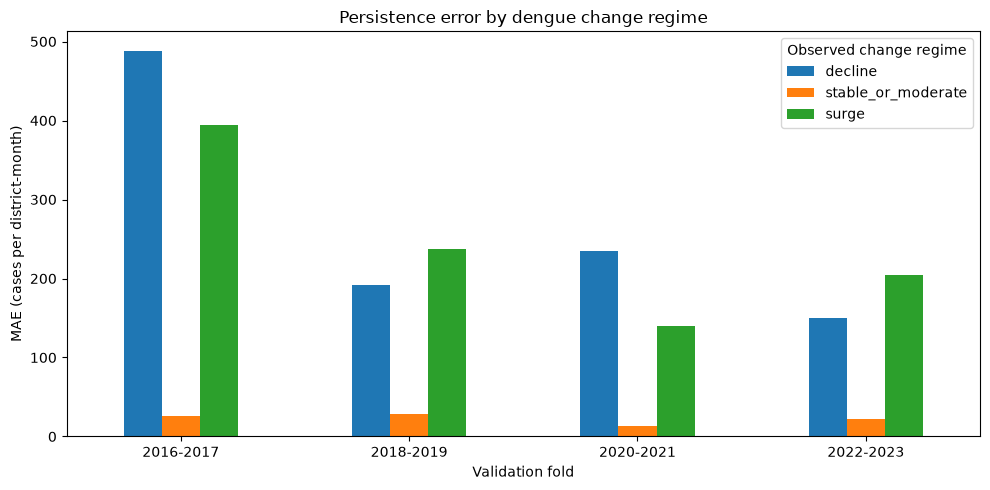

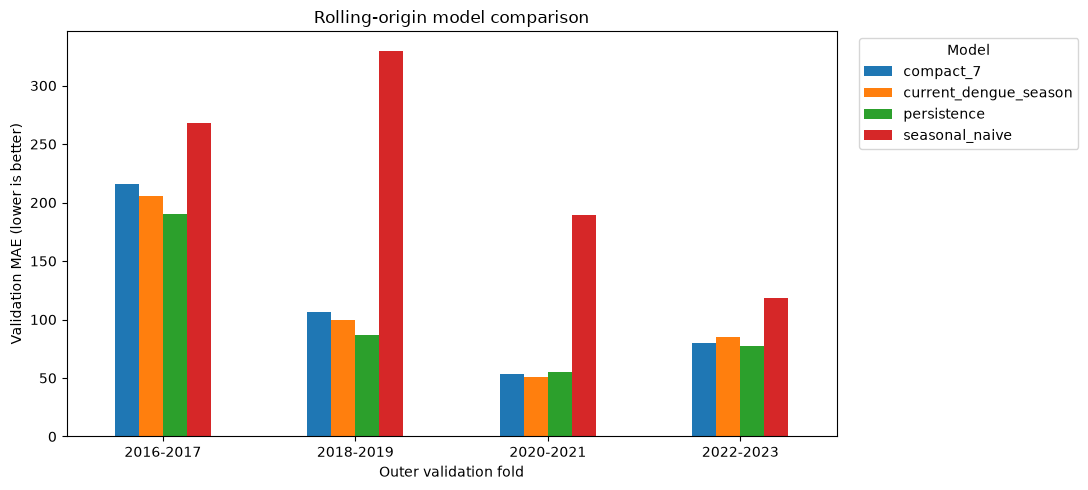

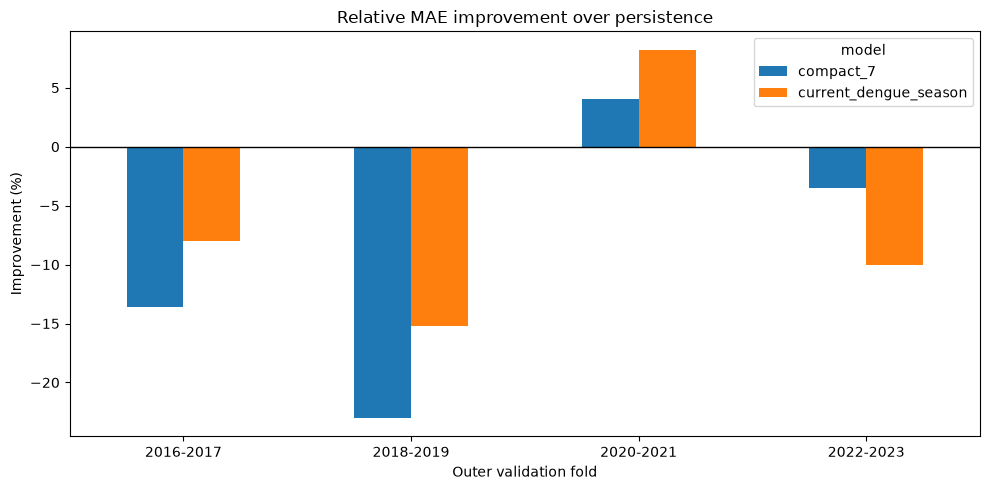

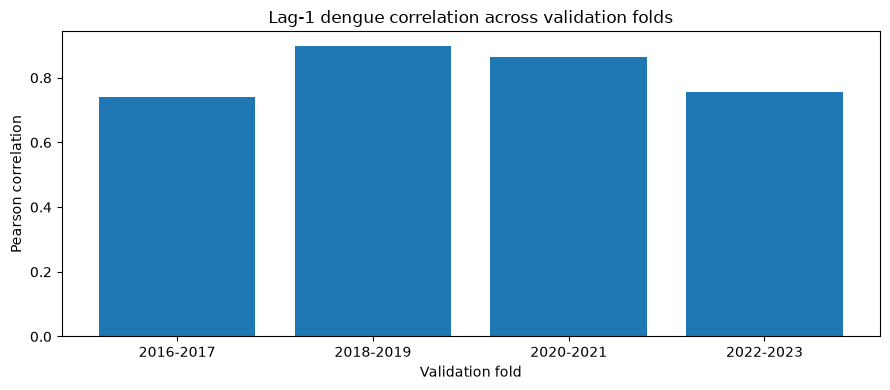

In [13]:
# Figure 1 — Persistence MAE by fold and regime
plot=regime_metrics.query("model == 'persistence'").pivot(index='fold',columns='regime',values='MAE_cases')
plot=plot.reindex([x[0] for x in FOLDS])
ax=plot.plot(kind='bar',figsize=(10,5),rot=0)
ax.set(title='Persistence error by dengue change regime',ylabel='MAE (cases per district-month)',xlabel='Validation fold')
ax.legend(title='Observed change regime');plt.tight_layout()
plt.savefig(FIGS/'notebook20_persistence_regime_errors.png',dpi=160,bbox_inches='tight');plt.show()

# Figure 2 — Per-fold model MAE
order=[x[0] for x in FOLDS]
pivot=summary.pivot(index='fold',columns='model',values='MAE_mean').reindex(order)
ax=pivot.plot(kind='bar',figsize=(11,5),rot=0)
ax.set(title='Rolling-origin model comparison',ylabel='Validation MAE (lower is better)',xlabel='Outer validation fold')
ax.legend(title='Model',bbox_to_anchor=(1.02,1),loc='upper left');plt.tight_layout()
plt.savefig(FIGS/'notebook20_fold_model_MAE.png',dpi=160,bbox_inches='tight');plt.show()

# Figure 3 — Improvement over persistence, zero = equal
plot=summary.query("model in ['current_dengue_season','compact_7']")
ax=plot.pivot(index='fold',columns='model',values='improvement_vs_persistence_pct').reindex(order).plot(
    kind='bar',figsize=(10,5),rot=0)
ax.axhline(0,color='black',lw=1)
ax.set(title='Relative MAE improvement over persistence',ylabel='Improvement (%)',xlabel='Outer validation fold')
plt.tight_layout();plt.savefig(FIGS/'notebook20_improvement_vs_persistence.png',dpi=160,bbox_inches='tight');plt.show()

# Figure 4 — Correlation and persistence MAE
pooled=autocorr.query("district == 'ALL_POOLED'").set_index('fold').reindex(order)
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(pooled.index,pooled.pearson_lag1)
ax.set(title='Lag-1 dengue correlation across validation folds',ylabel='Pearson correlation',xlabel='Validation fold')
plt.tight_layout();plt.savefig(FIGS/'notebook20_lag1_correlation.png',dpi=160,bbox_inches='tight');plt.show()

## 14 — Save research tables and the complete protocol

All files have a `notebook20_` prefix to avoid overwriting earlier experiments. **No 2024 evaluation is performed.** The JSON captures modeling choices and limitations for the Methods section of your paper.

In [14]:
files={
    'notebook20_fold_definition.csv':fold_table,
    'notebook20_lag1_autocorrelation.csv':autocorr,
    'notebook20_baseline_metrics.csv':baseline_metrics,
    'notebook20_lstm_seed_metrics.csv':model_metrics,
    'notebook20_fold_model_summary.csv':summary,
    'notebook20_weather_matched_contrasts.csv':pair,
    'notebook20_regime_metrics.csv':regime_metrics,
    'notebook20_high_incidence_metrics.csv':incidence_metrics,
    'notebook20_district_metrics.csv':district_metrics,
    'notebook20_month_block_bootstrap.csv':bootstrap,
    'notebook20_predictions.csv':all_predictions,
}
for name,table in files.items():
    table.to_csv(TABLES/name,index=False)
    print('Saved:',(TABLES/name).relative_to(ROOT),'rows:',len(table))
protocol={
 'notebook':'20_rolling_origin_persistence_analysis',
 'task':'one-month-ahead district-level dengue cases',
 'status':'retrospective exploratory validation, not an untouched independent test',
 '2024_accessed_for_training_or_evaluation':False,
 'feature_source':str(FEATURE_PATH.relative_to(ROOT)),
 'baseline_source':str(RAW_PATH.relative_to(ROOT)),
 'target':TARGET,'sequence_months':SEQ_LEN,
 'folds':[{'name':a,'train_target_end':b,'validation_start':c,'validation_end':d} for a,b,c,d in FOLDS],
 'internal_validation_months':INTERNAL_VAL_MONTHS,
 'scaler':'StandardScaler fitted on inner-fitting sequences only, separately for each fold/model',
 'target_transform':'log1p; inverse via max(0,expm1(pred))',
 'architecture':'LSTM(32)-Dense(16,relu)-Dropout(0.2)-Dense(1)',
 'seeds':list(SEEDS),'max_epochs':MAX_EPOCHS,'patience':PATIENCE,
 'batch_size':BATCH_SIZE,'learning_rate':LEARNING_RATE,'dropout':DROPOUT,
 'feature_groups':FEATURE_GROUPS,
 'regime_rule':'absolute change >=50 cases AND relative change >=25% of max(previous,1)',
 'high_incidence_rule':'90th percentile of pre-fold training target cases',
 'bootstrap':'resample 24 calendar-month blocks within fold; exploratory only',
 'limitations':['2024 previously inspected; no new independent test claimed',
                'Only three training seeds by default',
                'Inner last-year validation excluded from gradient fitting',
                'Weather measurements for month t assumed available at end of t',
                'Month-block bootstrap ignores longer temporal dependence',
                'Weekly cases were proportionally allocated to calendar months upstream']
}
path=METRICS/'notebook20_protocol.json'
path.write_text(json.dumps(protocol,indent=2),encoding='utf-8')
print('Saved:',path.relative_to(ROOT))
assert all_predictions.target_date.max()<pd.Timestamp('2024-01-01')
assert set(all_predictions.fold)==set(x[0] for x in FOLDS)
print('ALL NOTEBOOK 20 OUTPUT CHECKS PASSED')

Saved: results\tables\notebook20_fold_definition.csv rows: 4
Saved: results\tables\notebook20_lag1_autocorrelation.csv rows: 104
Saved: results\tables\notebook20_baseline_metrics.csv rows: 8
Saved: results\tables\notebook20_lstm_seed_metrics.csv rows: 24
Saved: results\tables\notebook20_fold_model_summary.csv rows: 16
Saved: results\tables\notebook20_weather_matched_contrasts.csv rows: 12
Saved: results\tables\notebook20_regime_metrics.csv rows: 96
Saved: results\tables\notebook20_high_incidence_metrics.csv rows: 64
Saved: results\tables\notebook20_district_metrics.csv rows: 800
Saved: results\tables\notebook20_month_block_bootstrap.csv rows: 24
Saved: results\tables\notebook20_predictions.csv rows: 19200
Saved: results\metrics\notebook20_protocol.json
ALL NOTEBOOK 20 OUTPUT CHECKS PASSED


## 15 — How to interpret your findings for the paper

**Main comparison:** Inspect `notebook20_fold_model_summary.csv`. A **positive** `improvement_vs_persistence_pct` means that model achieved **lower MAE** than persistence in that fold. Count the folds where the compact LSTM wins; compare the size of improvements and losses, not just their number.

**Why persistence may work:** `notebook20_lag1_autocorrelation.csv` quantifies temporal continuity. `notebook20_regime_metrics.csv` reveals whether persistence errors concentrate in surges and declines. Strong lag-1 correlation does **not** establish that persistence is optimal or that dengue dynamics are stationary.

**Weather contribution:** `notebook20_weather_matched_contrasts.csv` compares identical LSTM architecture and target cohorts using 3 versus 7 predictors. Positive `MAE_3_minus_7` indicates a benefit from adding four current weather measurements. If the effect varies across folds, report the heterogeneity; do not average away reversals.

**Outbreak usefulness:** `notebook20_high_incidence_metrics.csv` evaluates MAE and signed bias on high-incidence observations, using a training-only threshold. Because these strata are defined using observed outcomes, this is **error characterization**, not outbreak detection performance. To claim operational early-warning performance, predefine alert thresholds and calculate sensitivity/precision using forecasts.

**Uncertainty:** Three training seeds and an exploratory month-block bootstrap are useful robustness checks, not conclusive hypothesis tests. A strong paper would additionally test equal-budget hyperparameter searches, more seeds, and a genuinely later untouched dataset.

**Potential manuscript sentence (fill in after execution):**

> “In four expanding-window retrospective validation folds spanning 2016–2023, we compared persistence, seasonal naïve forecasts, and matched 3- and 7-feature LSTM models using training-only scaling and internal early stopping. **The relative ranking varied across evaluation periods**, with persistence achieving the lowest mean absolute error (MAE) in three of the four folds, while the 3-feature LSTM performed best during 2020–2021. Feature ablation showed that **adding four weather variables did not consistently improve forecasting performance**, reducing MAE in only 4 of 12 matched training runs. Error stratification revealed that **persistence performed particularly well during stable or moderately changing dengue periods but experienced substantially larger errors during sudden surges and declines**. The LSTM models reduced forecasting errors during sharp declines but generally underestimated sudden increases in dengue incidence. Overall, these findings suggest that recent dengue incidence provides a strong forecasting baseline and that additional environmental features and neural network complexity do not guarantee improved short-term predictive accuracy.”

Lag-1 Pearson correlations ranged from 0.741 to 0.899 across the four validation periods, indicating substantial month-to-month dependence in district-level dengue incidence. This temporal dependence may help explain the strong performance of persistence forecasting, particularly during periods without abrupt changes in dengue case counts.

**Important:** Do not fill the bracketed findings before running the notebook. If the compact LSTM fails to beat persistence, that is a valid negative result, not a failed research project.